In [1]:
import math
import numpy as np
from numpy import linalg as LA
from qiskit import QuantumRegister, QuantumCircuit, ClassicalRegister, transpile
from qiskit import quantum_info as qi
from qiskit_aer import Aer
from qiskit.visualization import plot_histogram, array_to_latex
from qiskit.circuit.library import Initialize, PauliEvolutionGate

#### Function definitions for QFT and inverse QFT

In [2]:
def qft_rotations(circuit, n):
    """Performs qft on the first n qubits in circuit (without swaps)"""
    if n == 0:
        return circuit
    n -= 1
    circuit.h(n)
    for qubit in range(n):
        circuit.cp(math.pi/2**(n-qubit), qubit, n)
    # At the end of our function, we call the same function again on
    # the next qubits (we reduced n by one earlier in the function)
    qft_rotations(circuit, n)
    
def swap_registers(circuit, n):
    for qubit in range(n//2):
        circuit.swap(qubit, n-qubit-1)
    return circuit

def qft(circuit, n):
    """QFT on the first n qubits in circuit"""
    qft_rotations(circuit, n)
    swap_registers(circuit, n)
    return circuit

def inverse_qft(circuit, n):
    """Does the inverse QFT on the first n qubits in circuit"""
    # First we create a QFT circuit of the correct size:
    qft_circ = qft(QuantumCircuit(n), n)
    # Then we take the inverse of this circuit
    invqft_circ = qft_circ.inverse()
    # And add it to the first n qubits in our existing circuit
    circuit.append(invqft_circ, circuit.qubits[:n])
    return circuit.decompose() # .decompose() allows us to see the individual gates

#### A Hermitian matrix used to create the unitary operator $U=e^{iA}$

In [3]:
A = np.array([[15,  9,  5, -3],
              [ 9, 15,  3, -5],
              [ 5,  3, 15, -9],
              [-3, -5, -9, 15],
             ])

#### Find the eigenvalues and the eigenvectors by classical methods

In [4]:
w, v = LA.eigh(A)
print("Eigenvalues: \n", w)
print("Eigenvectors: \n", v)

Eigenvalues: 
 [ 4.  8. 16. 32.]
Eigenvectors: 
 [[-0.5  0.5 -0.5 -0.5]
 [ 0.5 -0.5 -0.5 -0.5]
 [ 0.5  0.5  0.5 -0.5]
 [ 0.5  0.5 -0.5  0.5]]


$\bullet~$ extract the eigenvectors (see remark from Math_03)

In [5]:
v0 = np.array([[v[0][0]], [v[1][0]], [v[2][0]], [v[3][0]]])
v1 = np.array([[v[0][1]], [v[1][1]], [v[2][1]], [v[3][1]]])
v2 = np.array([[v[0][2]], [v[1][2]], [v[2][2]], [v[3][2]]])
v3 = np.array([[v[0][3]], [v[1][3]], [v[2][3]], [v[3][3]]])

$\bullet~$ ...just checking that they are really eigenvectors corresponding to eigenvalues

In [6]:
#print(A.dot(v0) - w[0]*v0)
#print(A.dot(v1) - w[1]*v1)
#print(A.dot(v2) - w[2]*v2)
#print(A.dot(v3) - w[3]*v3)

#### The dimension of $A$ is $2^{2} \times 2^{2}$, therefore we need two qubits to store the eigenvector

In [7]:
nb = 2

#### We want to calculate the eigenvalue (the phase) with a precision of 5 binary digits

In [8]:
# counting qubits
n = 5
N = 2**n

#### In order to have phases which are exact multiples of $2 \pi$, we use the following trick:

$\bullet~$ define a negative evolution time $t = - 2 \pi / (w N)$ and create the evolution operator $U = \exp(-i A t)$

$\bullet~$ the eigenvalues of $U$ will be $\exp(-i w t)$, where $w$ is the chosen eigenvalue of $A$: $~\exp( i 2 \pi / N)$

$\bullet~$ the QPE algorithm finds eigenvalues of the form $\exp(i \phi)$ with $\phi = 2 \pi a / N$, with $a = 0, 1, 2, \ldots , N-1$ with $N=2^{n}$

#### Choose an eigenvalue and calculate the parameter $t$

In [9]:
ev = 4
t = - 2 * math.pi / ev * (1/N)

#### get the corresponding eigenvector and create a statevector

In [10]:
psi_0 = qi.Statevector(np.array([-0.5, 0.5, 0.5, 0.5])) ## for eigenvalue = 4
psi_1 = qi.Statevector(np.array([0.5, -0.5, 0.5, 0.5])) ## for eigenvalue = 8
psi_2 = qi.Statevector(np.array([-0.5, -0.5, 0.5, -0.5])) ## for eigenvalue = 16
psi_3 = qi.Statevector(np.array([-0.5, -0.5, -0.5, 0.5])) ## for eigenvalue = 32

psi = psi_0

#psi = 0.5 * (psi_0 + psi_1 + psi_2 + psi_3)

array_to_latex(psi, prefix="|\\psi\\rangle =")

<IPython.core.display.Latex object>

#### Build the circuit

In [11]:
regv = QuantumRegister(n,  'regv')
regu = QuantumRegister(nb, 'regu')
creg = ClassicalRegister(n)
qc = QuantumCircuit(regv, regu, creg)

$\bullet~$ apply Hadamard gates on the counting qubits

In [12]:
qc.h(regv)

$\bullet~$ initialize with the eigenvector

In [13]:
init_gate = Initialize(psi)
init_gate.label = "init"
qc.append(init_gate, regu)

In [14]:
pop = qi.SparsePauliOp.from_operator(A)
pop_evo = PauliEvolutionGate(pop, time=t)

$\bullet~$ build the controlled version of the operator U (use a temporary circuit)

In [15]:
rq_u = QuantumRegister(nb)
qc_u = QuantumCircuit(rq_u)
qc_u.append(pop_evo, rq_u)
u_gate = qc_u.to_gate()
cu_gate = qc_u.to_gate().control(1)

$\bullet~$ apply the controlled U operator

In [16]:
repetitions = 1
for counting_qubit in range(n):
    for i in range(repetitions):
        qc.append(cu_gate, [counting_qubit, n, (n+1)]); # This is C-U !!!
    repetitions *= 2

$\bullet~$ apply the inverse QFT

In [17]:
qc.barrier()
inverse_qft(qc, n)

$\bullet~$ measure the counting qubits

In [18]:
qc.barrier()
qc.measure(regv, creg)

#### Run a simulation and measure

In [19]:
backend = Aer.get_backend('qasm_simulator')
job = backend.run(transpile(qc, backend), shots=2048)
results = job.result()
counts = results.get_counts()

In [20]:
print(counts)

{'00001': 2048}


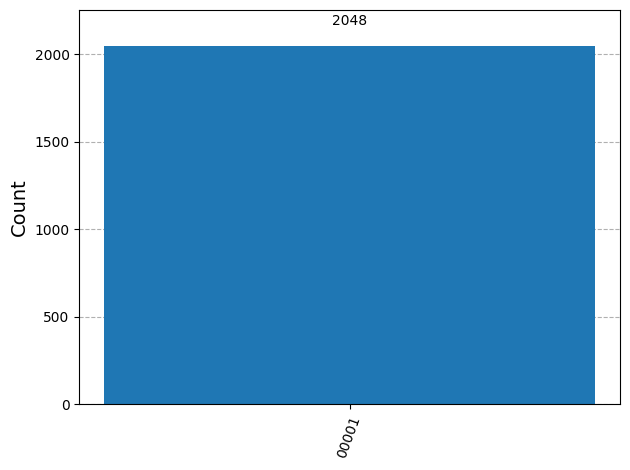

In [21]:
plot_histogram(counts)

In [22]:
from qiskit_ibm_runtime.fake_provider import FakeAachen

In [24]:
backend = FakeAachen()
job = backend.run(transpile(qc, backend), shots=2048)
results = job.result()
counts = results.get_counts()

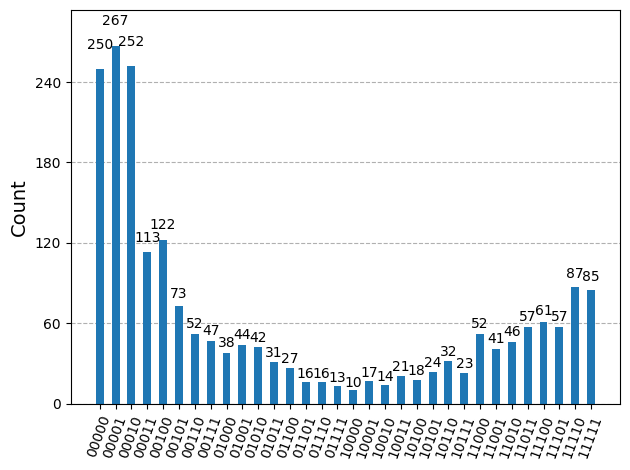

In [25]:
plot_histogram(counts)

In [23]:
import tutorial_magics
%qiskit_version_table